In [21]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

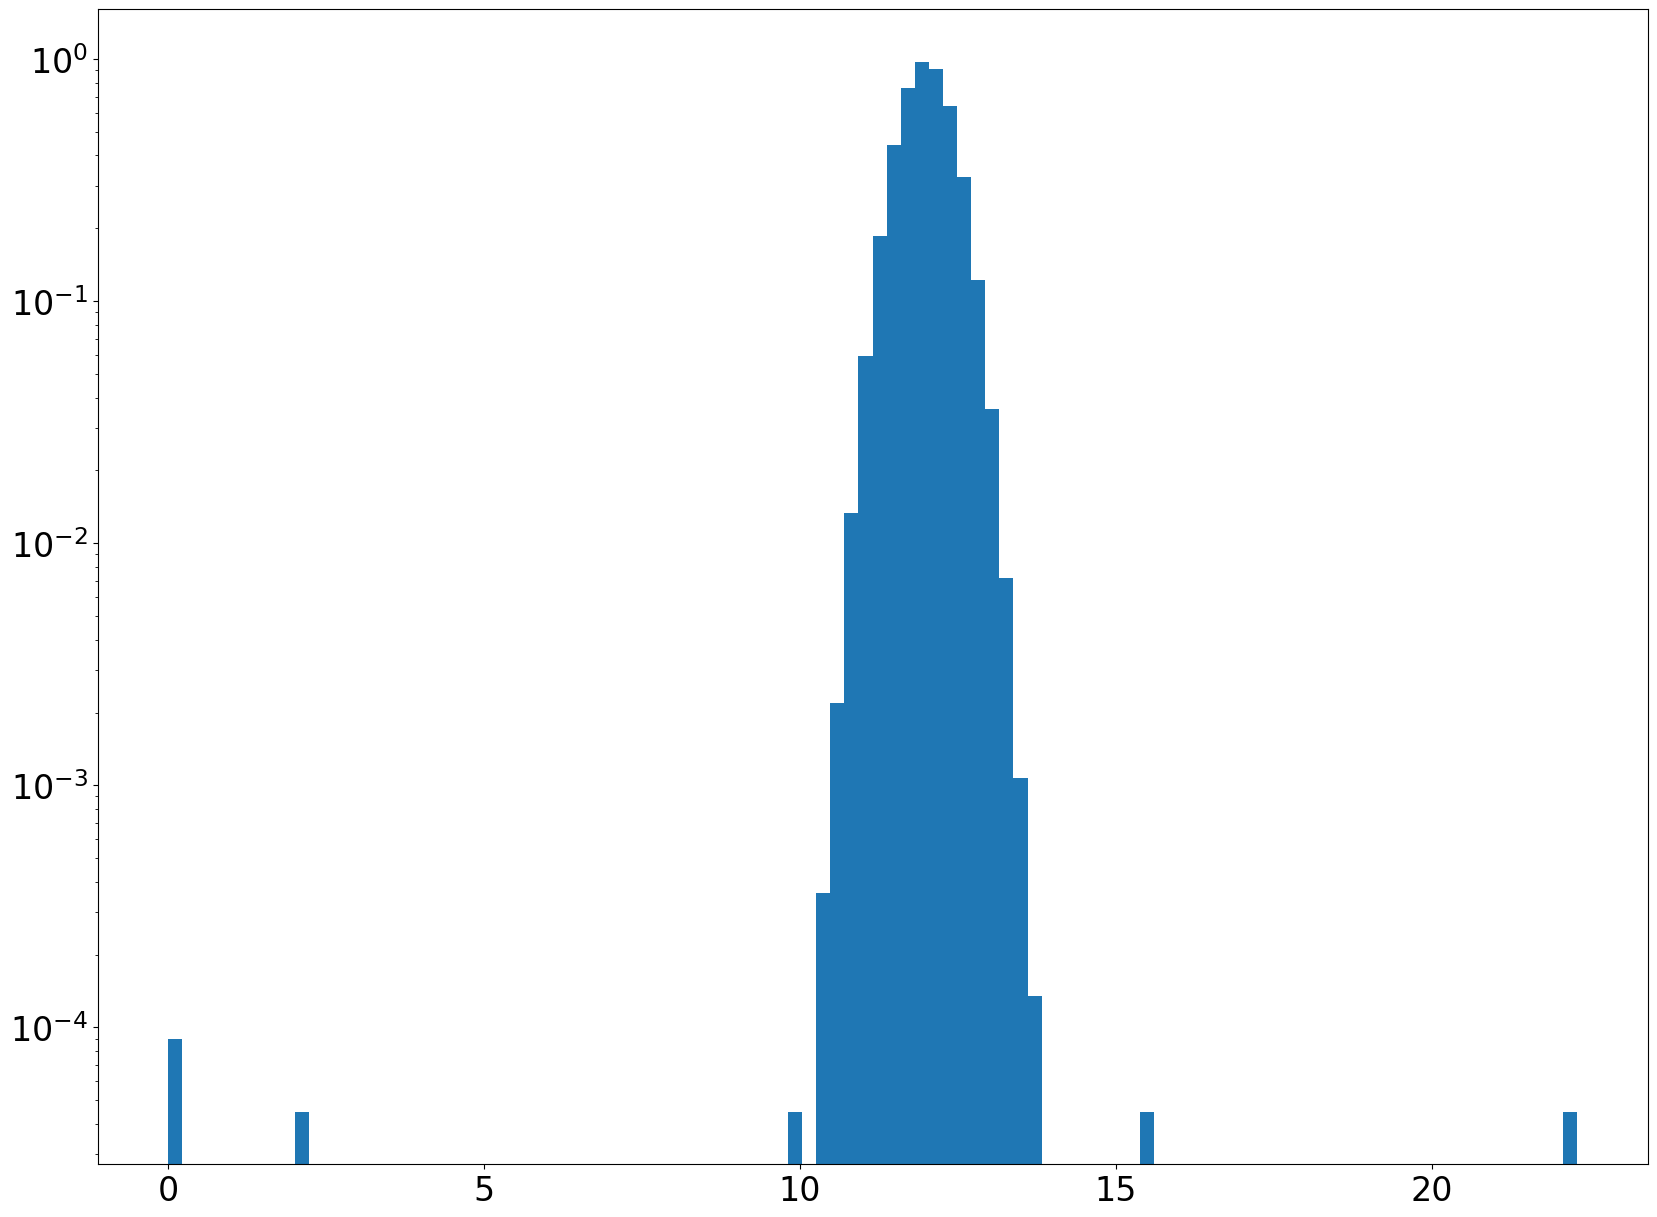

In [22]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

### For a temerature reading normal distribution with an averge of 12Kelvin and with a standard deviation of 0.4, what is the probability the reading is signficant (over 5 sigma)? I choose this question because knowing the Bad data is not enough. It is critical to know how significant(percentage) the bad data is in the distribution. 

In [23]:
P = 2 * stats.norm.sf(12+4*0.4, loc = 12, scale = 0.4) 
print(P)

6.334248366623996e-05


P(reading>5sig+ reading<5sig) = 1- (integral of normal distribution from 12-5sigma to 12+5sigma) 

In [24]:
Tbad = P*100000
Tgood = 100000*(1-2 * stats.norm.sf(12+4*0.4, loc = 12, scale = 0.4))
print("Your Test Bad is",round(Tbad))
print("Your Test Good is",round(Tgood))
TrueN = np.array([10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
TrueB= TrueN.size
TrueT = 100000 - TrueB
print("True T is ",TrueT)
print("True B is ",TrueB)

Your Test Bad is 6
Your Test Good is 99994
True T is  99992
True B is  8


In [25]:
P = 2 * stats.norm.sf(12+4*0.3, loc = 12, scale = 0.4) 
Tbad = P*100000
Tgood = 100000*(1-2 * stats.norm.sf(12+4*0.3, loc = 12, scale = 0.4))
print("Your Test Bad is",round(Tbad))
print("Your Test Good is",round(Tgood))

Your Test Bad is 270
Your Test Good is 99730


In [26]:
P = 2 * stats.norm.sf(12+4*0.5, loc = 12, scale = 0.4) 
Tbad = P*100000
Tgood = 100000*(1-2 * stats.norm.sf(12+4*0.5, loc = 12, scale = 0.4))
print("Your Test Bad is",round(Tbad))
print("Your Test Good is",round(Tgood))

Your Test Bad is 0
Your Test Good is 100000


### b) Because if I change the threshhold from 4 sigma to 3 sigma, the number of bad data increases from 6 to 270; simularly, when i change the threshold to 5 sigma, the predicted bad test data drops to one. Therefore, the number of good/bad data depends on how you choose the threshold (nomarlly it's how many standard devietion apart from the average). 

### 

### according to the 2D Histogram of positional uncertainity that corresponds to a rayleigh distribution of mean 0 and standard deviation of 1, what the possibility that a position uncertinity in 2D background is significant (5 sigma away from the average)? 

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_1005/2121784878.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
/tmp/ipykernel_1005/2121784878.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel("$\Delta$x arcseconds", fontsize = 18)


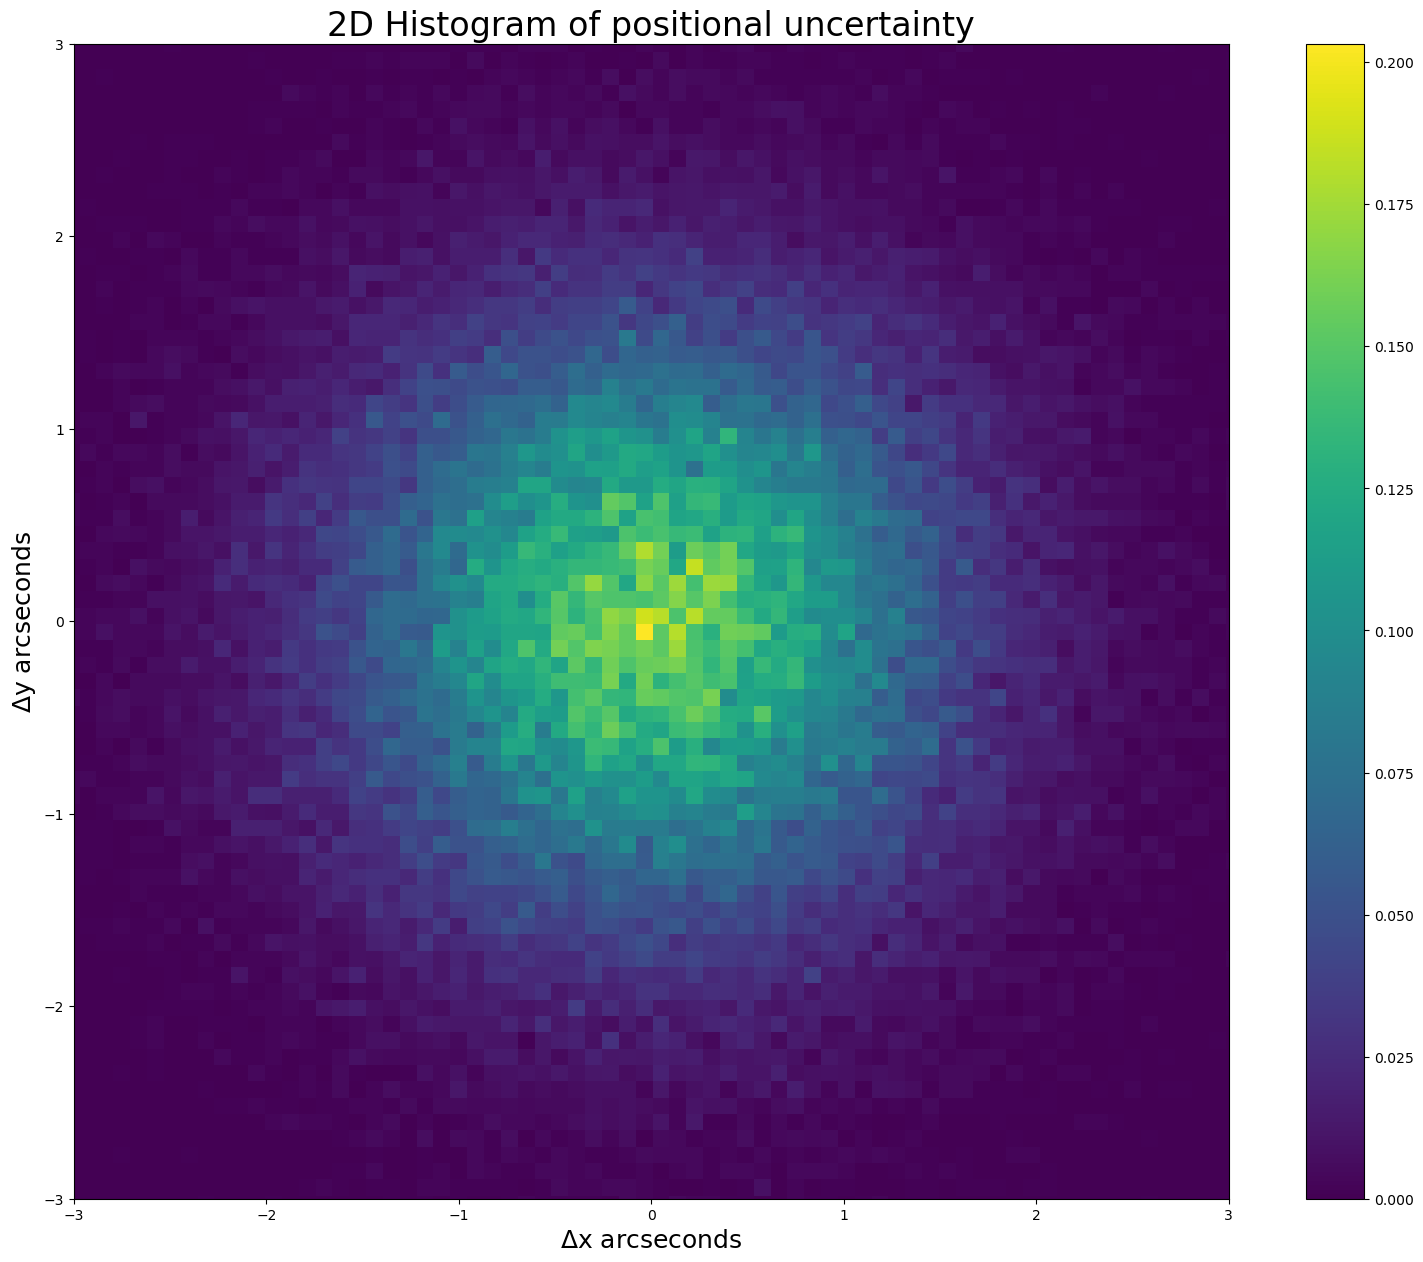

In [27]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
plt.xlabel("$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

In [28]:
P = 2 * stats.rayleigh.sf(5, loc = 0, scale = 1) 
print(P)

7.453306344157342e-06


### The analytic form will be 1 minute the integral of rayleigh distribution with a sd of 1 and average at0  from 0 to 5. 

### a vector pointing from 0 to a magnitude 5 of sqrt(delta x* arseconds +delta y* arseconds) on 2D Histogram of positional uncertainity represents 5 sigma detection of motion. In this case 5 sigma detection of motion correspond to a length 5 arcsenconds vector on the 2d Historgram, because sigma is 1 arsecond.  

### Problem 3

### we want to know what's the (how significant) probability from observing 6800 cosmics rays in 15 days to infinity based on the the fact that we observe an averge 7200 cosmics rays per 15 days.

In [29]:
P = 1- (stats.poisson.cdf(7200, 6800))
print(P)

7.462549663772577e-07


### we compute formula P (X>= 7200) = intergral of 7200 to infinity (lambda^X times e^- lambda)/ K!, where lambda is 6800  

In [30]:
Ppossion = stats.poisson.cdf(7200, 6800)
sigma = stats.norm.ppf(Ppossion,loc=0,scale=1)
print(sigma)

4.812235953879914
